# Lab 1 — From data to probability

**Lecture connections: weeks 1–3.**

Use data to describe a group, choose an appropriate source and interpret a conditional probability.
By the end, you should be able to identify the observational unit, defend a summary or plot,
and explain why reversing a condition changes a probability.

**Activities**

1. Choose an Edinburgh database and define one row
2. Compare spatial-memory measurements
3. Describe bank records and examine selection
4. Conditional probability, total probability and Bayes
5. Observe the law of large numbers
6. Write your statistical conclusions

Run the supplied cells in order with **Shift+Enter**. Predict the result before running an experiment,
then discuss what it means with a partner. Write short answers in the response cells.
Python syntax support is in `python-fundamentals/Python-fundamentals.ipynb`.
The optional investigations after the exit task are for further practice.

## 1. Choose a data source

**Week 1: a research question determines the data you need.** These four services are available
through the [University of Edinburgh Library's Business databases page](https://library.ed.ac.uk/finding-resources/library-databases/databases-subject-a-z/databases-business).

| Service | What you can investigate | Getting started |
|---|---|---|
| **Wharton Research Data Services (WRDS)** | Research datasets such as Compustat company accounts, CRSP securities, BoardEx boards and ExecuComp remuneration | Register through the Library route with University details; approval can take three working days |
| **FAME** | UK and Irish company accounts, ratios, sectors and peer comparisons | Use the Library link and choose University of Edinburgh; access works on and off campus |
| **S&P Capital IQ Pro** | Global companies, banks and insurers: financial statements, market information, news and analytics | Follow the Library link and self-register with a University email address |
| **LSEG Workspace** | Market prices, Reuters news, company fundamentals, forecasts and Datastream time series | Apply through the Library page; eligibility covers Business School year 3/4 undergraduates and postgraduates |

Check the Library page for current access conditions. Further descriptions:
[Business School accounting and finance databases](https://www.business-school.ed.ac.uk/research/areas/accounting-finance/databases).

### From a database to an analysable table

A database is a source of measurements. Your statistical design specifies which measurements to select.
Before exporting a table, write down:

1. **Question and population:** for example, the distribution of debt ratios among UK manufacturing companies in a specified year.
2. **Observational unit:** one company in one year, one security on one day, or one bank in one quarter.
3. **Variables and units:** debt, assets, currency, financial year and the definition of the ratio.
4. **Coverage:** which firms, dates or records are included, and how missing accounts or delisted firms are handled.

Save the query dates, filters, variable definitions and identifiers with your analysis.
Two rows for the same company in successive years form repeated observations: treating them as independent firms would misstate the sample size.

**Pair task.** Choose a starting source and define one row for each question:

- How do debt ratios vary across UK private manufacturing companies?
- How are US listed-company returns associated with accounting profitability?
- How do capital ratios differ across international banks?
- How did a market index and interest rates move around a policy announcement?

An account or download is unnecessary for this exercise; use the descriptions above.

<details>
<summary>Check your reasoning</summary>

FAME is a useful starting point for UK private-company comparisons; define a company–financial-year row.
WRDS offers CRSP and Compustat for the returns/accounts question; align security identifiers and reporting dates.
Capital IQ Pro fits the international-bank question; define bank–quarter or bank–year observations and comparable ratios.
Workspace fits market and interest-rate series; define a date, frequency and market close convention.
These are starting choices: inspect coverage before committing to a design.
An event-time pattern alone does not identify the causal effect of an announcement.

</details>

**Your response:** Choose one question. State its population, row definition, two variables and one coverage check.

## 2. Describe spatial memory

**Weeks 1–2: a measurement determines the interpretation of a summary.**
In this spatial-memory exercise, 27 participants studied a grid containing 18 objects and then replaced them.
`No. correct` counts exact placements; `City block score` adds horizontal and vertical distances
between true and recalled positions. Higher counts and lower distances indicate better performance.
`Study time` is measured in seconds. The recorded group labels are `Elderly` and `Young`.

**Predict:** Which summaries would change most if one study time were extremely large?
Which memory measure gives credit for a near miss?

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# Open the notebook from its own folder or from the repository root.
DATA = Path('.') if Path('spatial-memory.csv').exists() else Path('Lab1')
if not (DATA / 'spatial-memory.csv').exists():
    raise FileNotFoundError('Open this notebook from Lab1 or the repository root.')
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
pd.set_option('display.max_columns', 12)

In [2]:
spatial = pd.read_csv(DATA / 'spatial-memory.csv')
display(spatial.head())
display(spatial.groupby('Age group').size().rename('Participants'))
# Subject is an identifier. Averaging it would not measure memory.
measures = ['Study time', 'No. correct', 'City block score']
summary = spatial.groupby('Age group')[measures].agg(['mean', 'median', 'std'])
display(summary.round(2))

,Age group,Subject,No. correct,% correct,City block score,Study time
0,Elderly,1,9,50.0,17,75
1,Elderly,2,8,44.4,15,90
2,Elderly,3,9,50.0,21,40
3,Elderly,4,6,33.3,34,40
4,Elderly,5,5,27.8,35,25


Age group
Elderly    14
Young      13
Name: Participants, dtype: int64

Study time               No. correct              City block score  \
                mean median    std        mean median   std             mean   
Age group                                                                      
Elderly        50.71   42.5  22.52        7.50    8.0  1.16            27.71   
Young          98.85   95.0  29.66       11.15   11.0  3.13            14.46   

                        
          median   std  
Age group               
Elderly     27.5  9.67  
Young       12.0  9.92

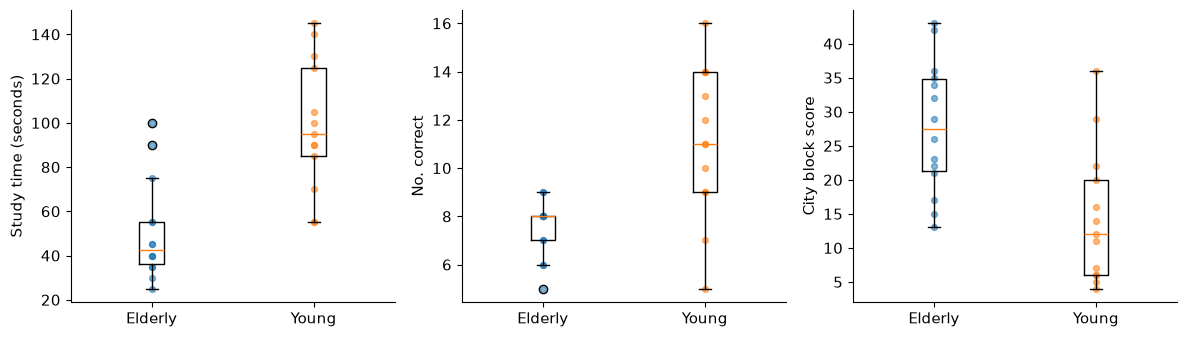

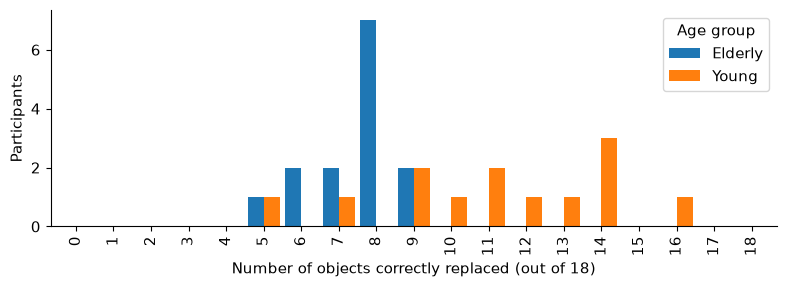

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
groups = ['Elderly', 'Young']
for ax, measure in zip(axes, measures):
    values = [spatial.loc[spatial['Age group'].eq(g), measure] for g in groups]
    ax.boxplot(values, tick_labels=groups)
    # Each dot is one participant, making the small group sizes visible.
    for j, y in enumerate(values, start=1):
        ax.scatter(np.full(len(y), j), y, alpha=0.55, s=18)
    ax.set_ylabel(measure + (' (seconds)' if measure == 'Study time' else ''))
fig.tight_layout()
plt.show()

frequency = pd.crosstab(spatial['No. correct'], spatial['Age group']).reindex(range(19), fill_value=0)
frequency.plot.bar(figsize=(8, 3), width=0.85)
plt.xlabel('Number of objects correctly replaced (out of 18)')
plt.ylabel('Participants')
plt.tight_layout()
plt.show()

**Discuss:** Compare the groups' centre and spread in study time and memory. Is the same group
higher on every numerical scale? Explain why a bar chart suits `No. correct` but becomes awkward
when almost every participant has a different study time.

The sample variance divides the sum of squared deviations by $n-1$; the SD is its square root
and has the measurement's original units. A boxplot shows quartiles and potential unusual values;
its shape alone does not establish a normal population.

<details>
<summary>Check your reasoning</summary>

Young participants spend longer studying on average and have a higher mean exact-placement count.
Their mean city-block score is lower. Time, exact hits and total distance measure different things.
Study time is treated as continuous; the two scores are counts. The city-block score distinguishes
near misses. These observational groups also differ in study time, so a group comparison does not isolate an age effect.

</details>

**Your response:** Report one difference with its units, one measure of spread and one reason to avoid a causal claim.

## 3. Bank records: distribution and selection

**Weeks 1–2: describe the records you have and identify the population you want.**
The local `bank-marketing.csv` contains six columns from all 45,211 records in
[UCI Bank Marketing](https://doi.org/10.24432/C5K306), by Moro, Rita and Cortez (CC BY 4.0).
A row summarises a campaign record and can include several contacts. `balance` is average yearly
balance in euros; `y` records term-deposit subscription. `unknown` is a recorded contact category.

**Predict:** In a distribution with a long upper tail, how will the mean compare with the median?

count      45211.00
mean        1362.27
median       448.00
std         3044.77
min        -8019.00
max       102127.00
Name: balance, dtype: float64

0.25      72.0
0.75    1428.0
Name: Quartiles in euros, dtype: float64

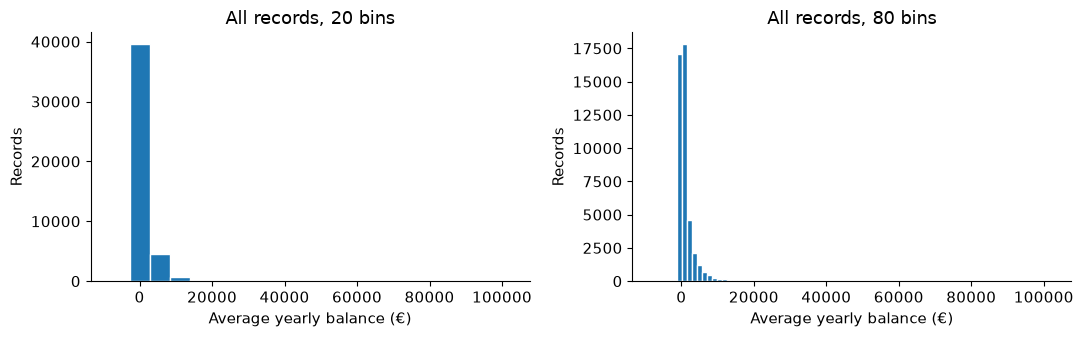

,all records,positive balances only
count,45211.00,37931.00
mean,1362.27,1655.27
median,448.00,644.00


In [4]:
bank = pd.read_csv(DATA / 'bank-marketing.csv')
balance = bank['balance']
display(balance.agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2))
display(balance.quantile([0.25, 0.75]).rename('Quartiles in euros'))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, bins in zip(axes, [20, 80]):
    # Both plots include every balance; only the bin width changes.
    ax.hist(balance, bins=bins, edgecolor='white')
    ax.set(title=f'All records, {bins} bins', xlabel='Average yearly balance (€)', ylabel='Records')
fig.tight_layout()
plt.show()

# This deliberately changes who is included: it is a selection experiment.
selection = pd.DataFrame({
    'all records': balance.agg(['count', 'mean', 'median']),
    'positive balances only': balance[balance > 0].agg(['count', 'mean', 'median'])
})
display(selection.round(2))

**Discuss:** Does changing the bin width change the mean? Does restricting to positive balances
change the target group? What additional information would justify applying these summaries to future bank customers?

<details>
<summary>Check your reasoning</summary>

Bin width changes the visual grouping, while the numerical summaries remain fixed.
Selecting positive balances changes the records and the population being described.
More selected records can reduce sampling variability while leaving selection bias.
The historical campaign file is not a random sample of all bank customers.

</details>

## 4. Reverse a condition

**Week 3: conditional probability changes the denominator.**
Let $H$ mean “has a housing loan” and $S$ mean “subscribed”. Choose one record uniformly
from this file. Compare $P(S\mid H)$ with $P(H\mid S)$.

**Predict:** Point to the appropriate denominator for each probability before calculating it.

In [5]:
housing = bank['housing'].eq('yes')
subscribed = bank['y'].eq('yes')
table = pd.crosstab(bank['housing'], bank['y']).reindex(index=['no', 'yes'], columns=['no', 'yes'])
display(table)

p_h = housing.mean()
p_s_given_h = subscribed[housing].mean()
p_s_given_not_h = subscribed[~housing].mean()
# Total probability sums the two disjoint routes to subscription.
p_s = p_s_given_h * p_h + p_s_given_not_h * (1 - p_h)
# Bayes uses the shared intersection, then divides by all subscriptions.
p_h_given_s = p_s_given_h * p_h / p_s
display(pd.Series({'P(H)': p_h, 'P(S)': p_s, 'P(S | H)': p_s_given_h,
                   'P(H | S), Bayes': p_h_given_s,
                   'P(H | S), direct count': housing[subscribed].mean()}))

personal = bank['loan'].eq('yes')
display(pd.Series({
    'P(housing or personal loan), direct': (housing | personal).mean(),
    'P(H) + P(L) - P(H and L)': housing.mean() + personal.mean() - (housing & personal).mean(),
    'P(H and S)': (housing & subscribed).mean(),
    'P(H)P(S), if independent': housing.mean() * subscribed.mean()
}))

y,no,yes
housing,,
no,16727,3354
yes,23195,1935


P(H)                      0.555838
P(S)                      0.116985
P(S | H)                  0.077000
P(H | S), Bayes           0.365854
P(H | S), direct count    0.365854
dtype: float64

P(housing or personal loan), direct    0.619473
P(H) + P(L) - P(H and L)               0.619473
P(H and S)                             0.042799
P(H)P(S), if independent               0.065025
dtype: float64

**Discuss:** What do the two routes in total probability represent? Which result would equality
of $P(H\cap S)$ and $P(H)P(S)$ indicate? Explain why a housing-loan/subscription association
does not establish the effect of giving a customer a housing loan.

<details>
<summary>Check your reasoning</summary>

About 7.7% of housing-loan records subscribed, while about 36.6% of subscribers had a housing loan.
The first denominator is housing-loan records; the second is subscriber records.
Total probability weights the subscription rates in the housing-loan and no-housing-loan groups by their shares.
Independence would require the joint probability to equal the product of the margins.
Bayes reverses conditioning using the same observations; it supplies no randomised intervention.

</details>

**Your response:** Explain the two percentages in words and show which count belongs in each denominator.

## 5. Probability through repetition

**Week 3: the law of large numbers.** Suppose independent loans have a constant default probability of 0.02.
These are simulated outcomes from a stated model. Predict whether the running proportion will
approach 0.02 smoothly or fluctuate. Does a run of repayments change the next loan's default probability?

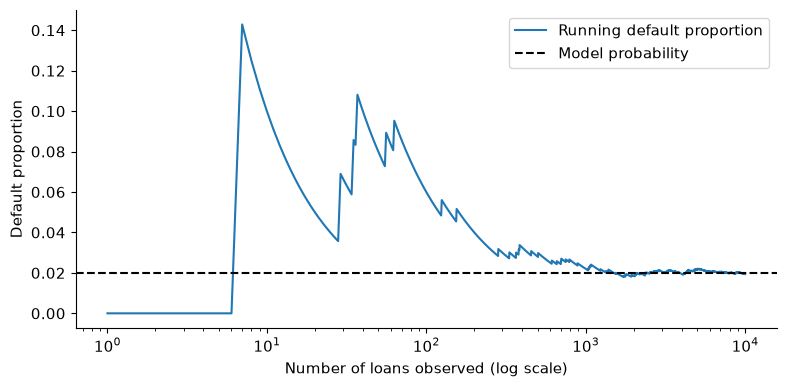

100      0.0600
1000     0.0220
10000    0.0194
dtype: float64

In [6]:
rng = np.random.default_rng(11624)
p_default = 0.02  # Change this probability, then rerun this cell.
defaults = rng.binomial(1, p_default, size=10000)
number_seen = np.arange(1, len(defaults) + 1)
running_rate = defaults.cumsum() / number_seen
plt.plot(number_seen, running_rate, label='Running default proportion')
plt.axhline(p_default, color='black', linestyle='--', label='Model probability')
plt.xscale('log')
plt.xlabel('Number of loans observed (log scale)')
plt.ylabel('Default proportion')
plt.legend()
plt.tight_layout()
plt.show()
display(pd.Series(running_rate[np.array([100, 1000, 10000]) - 1], index=[100, 1000, 10000]))

<details>
<summary>Check your reasoning</summary>

The running proportion fluctuates while becoming more stable around the model probability.
Its error need not decrease at every step. Independence and the fixed probability imply that
previous repayments leave the next default probability at 0.02.

</details>

## 6. Exit task

Write four sentences: name an Edinburgh data source and its observational unit; describe one
memory-group difference; interpret a conditional subscription probability; and explain what
larger samples improve under the independent-loan model.

**Your response:**

---

## Optional investigation A — Summaries, unusual values and graphical choices

**Week 2.** Predict the effect of a large extra study time on the mean, median, variance and IQR.
The extra value below is a deliberate hypothetical perturbation, not another participant.

,observed,with hypothetical 600 s
mean,73.89,92.68
median,70.00,72.50
SD,35.50,105.35
variance,1260.26,11099.04
IQR,55.00,56.25
range,120.00,575.00


Age group
Elderly     [8]
Young      [14]
Name: No. correct, dtype: object

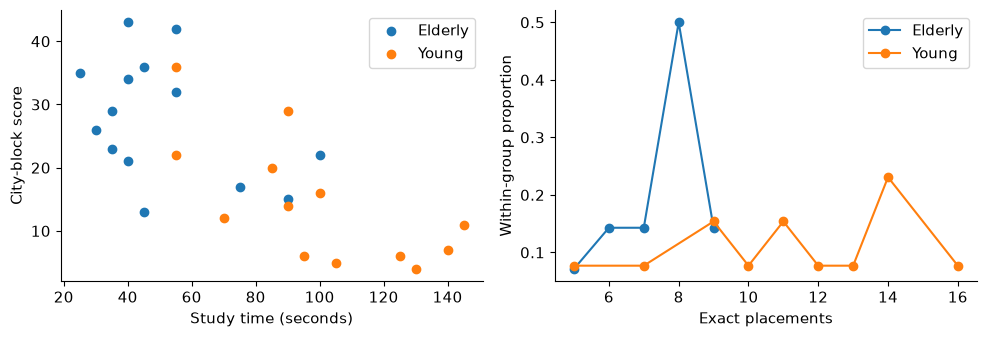

In [7]:
times = spatial['Study time']
def describe_values(values):
    return pd.Series({'mean': values.mean(), 'median': values.median(),
                      'SD': values.std(ddof=1), 'variance': values.var(ddof=1),
                      'IQR': values.quantile(0.75) - values.quantile(0.25),
                      'range': values.max() - values.min()})
display(pd.DataFrame({'observed': describe_values(times),
                      'with hypothetical 600 s': describe_values(pd.concat([times, pd.Series([600])]))}).round(2))
# Report all modes when several values tie for the highest frequency.
display(spatial.groupby('Age group')['No. correct'].agg(lambda x: list(x.mode())))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for group in ['Elderly', 'Young']:
    subset = spatial[spatial['Age group'].eq(group)]
    axes[0].scatter(subset['Study time'], subset['City block score'], label=group)
    # Divide by each group's size when comparing distributions with unequal totals.
    subset['No. correct'].value_counts(normalize=True).sort_index().plot(ax=axes[1], marker='o', label=group)
axes[0].set(xlabel='Study time (seconds)', ylabel='City-block score')
axes[1].set(xlabel='Exact placements', ylabel='Within-group proportion')
for ax in axes: ax.legend()
plt.tight_layout()
plt.show()

The connected frequency points help compare profiles; their horizontal axis is a score, not time.
A scatterplot retains paired measurements for each participant. The mean and SD respond strongly
to a large value; the median and IQR are more resistant. Investigate unusual values before deciding whether to exclude them.

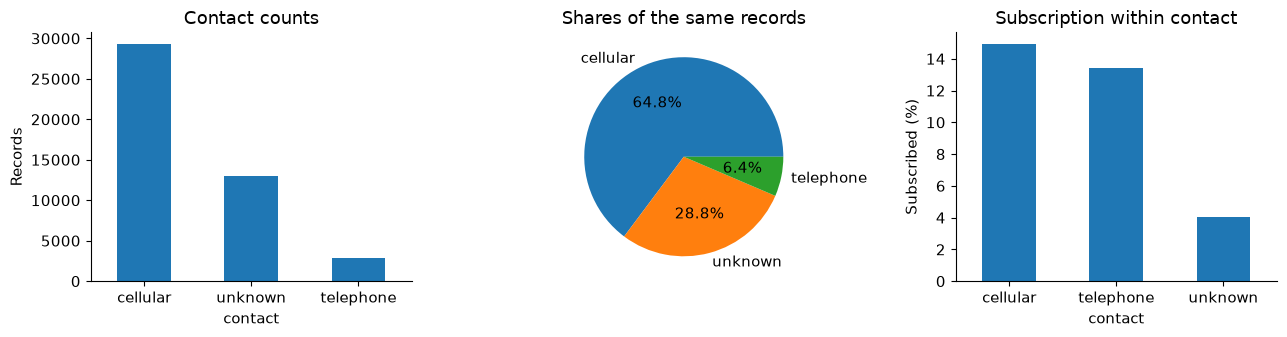

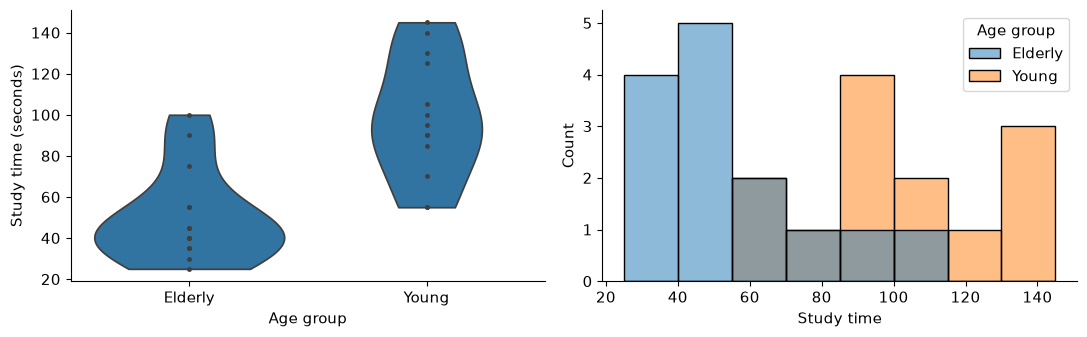

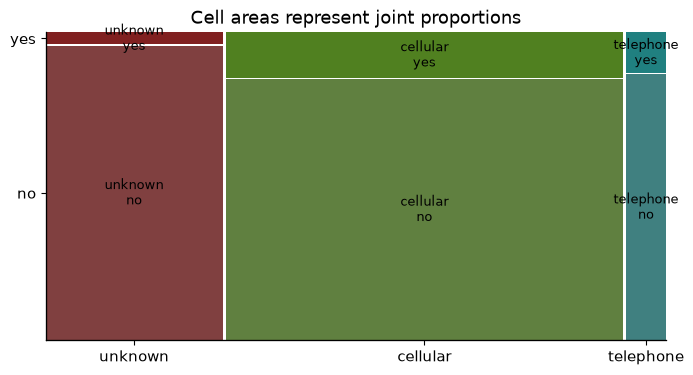

In [8]:
import seaborn as sns
from statsmodels.graphics.mosaicplot import mosaic

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
counts = bank['contact'].value_counts()
counts.plot.bar(ax=axes[0], rot=0, title='Contact counts', ylabel='Records')
axes[1].pie(counts, labels=counts.index, autopct='%1.1f%%')
axes[1].set_title('Shares of the same records')
rates = bank.assign(subscribed=bank['y'].eq('yes')).groupby('contact')['subscribed'].mean()
rates.mul(100).plot.bar(ax=axes[2], rot=0, title='Subscription within contact', ylabel='Subscribed (%)')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.violinplot(data=spatial, x='Age group', y='Study time', cut=0, inner='point', ax=axes[0])
axes[0].set_ylabel('Study time (seconds)')
sns.histplot(data=spatial, x='Study time', hue='Age group', bins=8, ax=axes[1])
plt.tight_layout()
plt.show()
mosaic(bank, ['contact', 'y'], title='Cell areas represent joint proportions')
plt.show()

Compare counts, overall shares and within-group subscription rates: their denominators differ.
The violin smooths a very small sample, so interpret its shape alongside the points.
In the mosaic, cell areas encode joint proportions and column heights encode conditional proportions.

## Optional investigation B — Base rates and expected losses

**Week 3.** A hypothetical review flag detects 80% of defaults and flags 10% of non-defaults.
Keep those two conditional probabilities fixed and vary the base rate. Predict the default
probability among flagged accounts.

In [9]:
sensitivity, false_positive_rate = 0.80, 0.10
base_rates = np.array([0.01, 0.05, 0.20])
p_flag = sensitivity * base_rates + false_positive_rate * (1 - base_rates)
display(pd.DataFrame({'base rate': base_rates, 'P(flag)': p_flag,
                      'P(default | flag)': sensitivity * base_rates / p_flag}))

# Two independent loans, each defaulting with probability 0.1; loss is £100 per default.
number_defaults = np.array([0, 1, 2])
probabilities = np.array([0.81, 0.18, 0.01])
loss = 100 * number_defaults
expected_loss = (loss * probabilities).sum()
variance_loss = ((loss - expected_loss)**2 * probabilities).sum()
print(f'Expected loss £{expected_loss:.2f}; variance {variance_loss:.2f} pounds squared; SD £{np.sqrt(variance_loss):.2f}')

,base rate,P(flag),P(default | flag)
0,0.01,0.107,0.074766
1,0.05,0.135,0.296296
2,0.20,0.240,0.666667


Expected loss £20.00; variance 1800.00 pounds squared; SD £42.43


<details>
<summary>Check your reasoning</summary>

The proportion of flags followed by default rises with the base rate, even with fixed conditional flag rates.
Expected loss is £20 and its SD is about £42.43. Expected loss is a probability-weighted average,
not a prediction that this two-loan portfolio will lose exactly £20.
For independent losses variances add; twice the same loss has four times the variance of one loss.

</details>

## Data guide

| File | One row | Fields |
|---|---|---|
| `spatial-memory.csv` | One participant, 27 rows | Age group, subject identifier, exact placements out of 18, rounded percentage correct, total city-block distance, study time in seconds |
| `bank-marketing.csv` | One campaign record, 45,211 rows | Age in years; average yearly balance in euros; housing/personal loan indicators; last contact category; subscription `y` |

Use the spatial-memory data to compare the 27 recorded participants. To make a population claim,
you would need to establish how participants were sampled from that population.
The bank data contain all 45,211 rows and the six listed columns of `bank-full.csv`, including
`unknown` categories and negative balances. Source: Moro, S., Rita, P. & Cortez, P. (2014),
[Bank Marketing](https://doi.org/10.24432/C5K306), UCI Machine Learning Repository, CC BY 4.0.